## 1. Cargar calibración y mapas (Tutorial 6, celda 53), con las claves que escribe la herramienta de la cátedra.

In [38]:
import os, glob, json, pickle
import cv2
import numpy as np
from matplotlib import pyplot as plt
from i308_utils import show_images


def read_img(path):
    # cv2.imread devuelve None con rutas no ASCII en Windows (ej. "Visión")
    if not os.path.exists(path):
        raise FileNotFoundError(f"No existe {path}")
    img = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"No se pudo decodificar {path}")
    return img


def write_img(path, img):
    ok, buf = cv2.imencode(os.path.splitext(path)[1], img)
    if not ok:
        raise ValueError(f"No se pudo codificar {path}")
    buf.tofile(path)

In [39]:
BASE = "." if os.path.isdir("datasets") else ".."

calib_file = os.path.join(BASE, "calibration", "stereo_calibration.pkl")
maps_file = os.path.join(BASE, "calibration", "stereo_maps.pkl")
captures_dir = os.path.join(BASE, "datasets", "stereo_stitch_charuco", "captures")
rect_dir = os.path.join(BASE, "datasets", "stereo_stitch_charuco", "rect")

with open(calib_file, "rb") as f:
    calibration = pickle.load(f)
with open(maps_file, "rb") as f:
    maps = pickle.load(f)

left_K, left_dist = calibration["left_K"], calibration["left_dist"]
right_K, right_dist = calibration["right_K"], calibration["right_dist"]
R, T = calibration["R"], calibration["T"]
print("image_size:", calibration["image_size"], " baseline:", np.linalg.norm(T).round(2), "mm")

left_map_x, left_map_y = maps["left_map_x"], maps["left_map_y"]
right_map_x, right_map_y = maps["right_map_x"], maps["right_map_y"]
P1, P2, Q = maps["P1"], maps["P2"], maps["Q"]

image_size: (1280, 720)  baseline: 60.17 mm


## 2. Rectificar un par y mirarlo

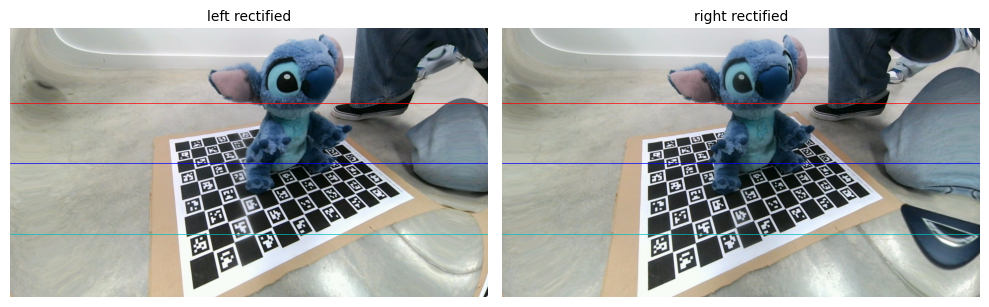

In [40]:
i = 13
left = read_img(os.path.join(captures_dir, f"left_{i}.jpg"))
right = read_img(os.path.join(captures_dir, f"right_{i}.jpg"))

left_rect = cv2.remap(left, left_map_x, left_map_y, cv2.INTER_LINEAR)
right_rect = cv2.remap(right, right_map_x, right_map_y, cv2.INTER_LINEAR)

fig, axes = show_images([left_rect, right_rect], ["left rectified", "right rectified"], show=False)
for y, c in zip([200, 360, 550], ["r", "b", "c"]):
    axes[0].axhline(y=y, color=c, linewidth=0.5)
    axes[1].axhline(y=y, color=c, linewidth=0.5)
plt.show()

## 3- Rectificar los 27 pares

In [41]:
os.makedirs(rect_dir, exist_ok=True)

def numero(path):
    return int(os.path.basename(path).split("_")[-1].split(".")[0])

left_files = sorted(glob.glob(os.path.join(captures_dir, "left_*.jpg")), key=numero)
for lf in left_files:
    idx = numero(lf)
    rf = os.path.join(captures_dir, f"right_{idx}.jpg")
    left_rect = cv2.remap(read_img(lf), left_map_x, left_map_y, cv2.INTER_LINEAR)
    right_rect = cv2.remap(read_img(rf), right_map_x, right_map_y, cv2.INTER_LINEAR)
    write_img(os.path.join(rect_dir, f"rect_left_{idx}.png"), left_rect)
    write_img(os.path.join(rect_dir, f"rect_right_{idx}.png"), right_rect)
print("listo:", len(left_files), "pares rectificados en", rect_dir)

listo: 27 pares rectificados en ..\datasets\stereo_stitch_charuco\rect


## 4- un json ni idea

In [42]:
h, w = left_rect.shape[:2]
calib_json = {
    "width": w, "height": h,
    "baseline_meters": float(np.linalg.norm(T)) / 1000,
    "fx": float(P1[0, 0]), "fy": float(P1[1, 1]),
    "cx0": float(P1[0, 2]), "cx1": float(P2[0, 2]), "cy": float(P1[1, 2]),
    "depth_range": [0.2, 3.0],
    "left_image_rect_normalized": [0, 0, 1, 1],
}
with open(os.path.join(rect_dir, "stereodemo_calibration.json"), "w") as f:
    json.dump(calib_json, f, indent=2)
print(json.dumps(calib_json, indent=2))

{
  "width": 1280,
  "height": 720,
  "baseline_meters": 0.06016896206128554,
  "fx": 405.88681301544904,
  "fy": 405.88681301544904,
  "cx0": 631.0462799072266,
  "cx1": 631.0462799072266,
  "cy": 352.4043731689453,
  "depth_range": [
    0.2,
    3.0
  ],
  "left_image_rect_normalized": [
    0,
    0,
    1,
    1
  ]
}
